# Notebook 07 — Evaluasi Model Lanjutan & *Error Analysis* Mendalam

**Lead Data Science:** Daniel Haganta Ginting (`41426090`)  
**Proyek:** Kelompok 25 — Dashboard Analitik & Prediksi Harga Cabai Merah Keriting di Pasar Tradisional Kota Medan  

Notebook ini melakukan evaluasi komprehensif terhadap 5 pendekatan pemodelan pada data uji *out-of-time* **2025–2026** (`2025-01-01` s.d. `2026-01-29`, $n = 282$ hari kerja) yang dilatih oleh `models/train.py`, serta membedah akar penyebab **10 galat prediksi (residual) terbesar** untuk merumuskan rekomendasi peningkatan model pada Minggu 13 dan kebijakan mitigasi TPID Kota Medan.

### Artefak Sumber (*Single Source of Truth*)
1. `../models/metrics.json` — Ringkasan hasil *Cross-Validation* (`TimeSeriesSplit(n_splits=5)`), metrik uji, *feature importance*, dan top-10 residual.
2. `../models/test_predictions.csv` — Prediksi harian 5 model pada 282 hari uji.
3. `../warehouse/cabai_medan.db` (SQL View `v_harga_lengkap`, dengan *auto-fallback* ke `../data/processed/01_clean.csv` & `01_cuaca_harian.csv`) — Konteks cuaca, harga hulu (Produsen & Pedagang Besar), serta jarak kalender ke Idul Fitri.

### Keluaran Grafik (`../docs/figures/`)
- `07_perbandingan_5_model.png`
- `07_diagnostik_prediksi_dan_residual.png`
- `07_error_per_rezim_dan_bulan.png`
- `07_top10_residual_dan_importance.png`

In [1]:
from pathlib import Path
import json
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

DATA_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
WH_DB = Path("../warehouse/cabai_medan.db")
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

with open(MODELS_DIR / "metrics.json", encoding="utf-8") as f:
    metrics = json.load(f)

pred_df = pd.read_csv(MODELS_DIR / "test_predictions.csv", parse_dates=["tanggal"])
print(f"Best model (berdasarkan CV MAE terendah): {metrics['best_model']}")
print(f"Strategi target: {metrics['strategi']}")
print(f"Baris prediksi uji: {len(pred_df)} ({pred_df['tanggal'].min().date()} s.d. {pred_df['tanggal'].max().date()})")


Best model (berdasarkan CV MAE terendah): Random Forest
Strategi target: Target perubahan harga harian (dy_t = y_t - Harga_Lag1), dikonversi ke Rupiah (Harga_Lag1 + dy_hat)
Baris prediksi uji: 282 (2025-01-01 s.d. 2026-01-29)


## 1. Perbandingan Kinerja 5 Model (CV *TimeSeriesSplit* vs Uji Masa Depan 2025–2026)

Pada `models/train.py`, seluruh model memprediksi perubahan harga harian $\Delta y_t = y_t - \text{Harga\_Lag1}$, lalu mengonversi kembali ke harga absolut $\hat{y}_t = \text{Harga\_Lag1} + \widehat{\Delta y}_t$. Pemilihan model terbaik menggunakan **CV MAE terendah** di `TimeSeriesSplit(n_splits=5)` pada periode latih (`2020-01-28` s.d. `2024-12-31`, $n=1.286$) untuk mencegah kebocoran pemilihan terhadap set uji.

,Model,Fitur,CV MAE (Rp),CV RMSE (Rp),CV MAPE (%),CV R2,Test MAE (Rp),Test RMSE (Rp),Test MAPE (%),Test R2,Waktu Latih (s)
0,Naive (Persistence),10,2297.01,4680.30,5.6225,0.91809,3340.43,5561.93,6.8655,0.90911,0.01
1,Ridge Regression (Baseline),10,2329.81,4662.23,5.7485,0.91872,3353.21,5532.61,6.9491,0.91006,0.22
2,Random Forest,12,2298.16,4679.74,5.6259,0.91811,3335.39,5558.99,6.8519,0.90920,33.29
3,XGBoost,12,2322.79,4667.59,5.7007,0.91854,3325.29,5541.36,6.8157,0.90978,14.69
4,LightGBM,12,2304.08,4669.43,5.6415,0.91847,3322.42,5535.51,6.7802,0.90997,9.75


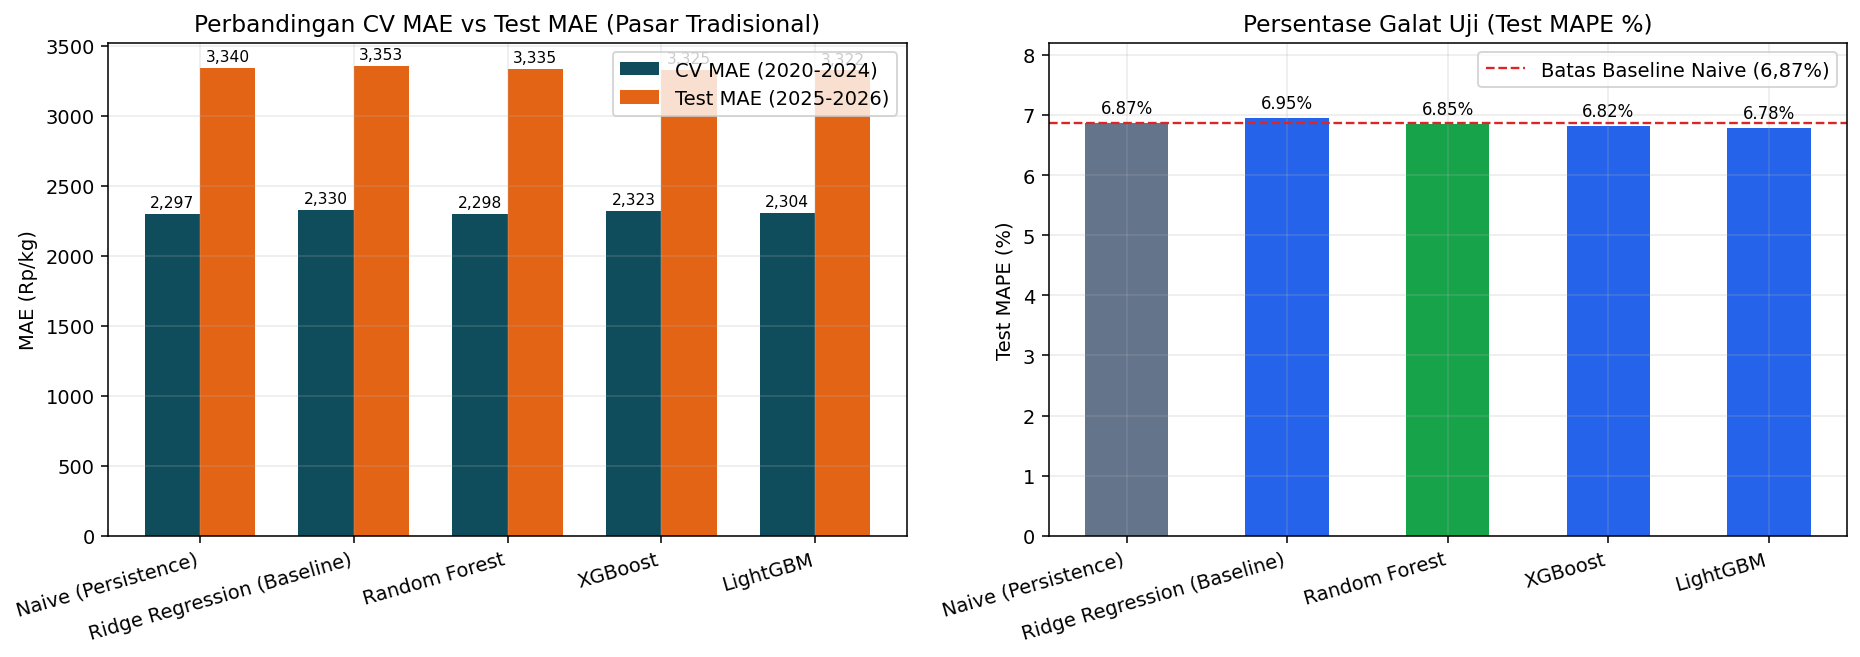

Tersimpan: ..\docs\figures\07_perbandingan_5_model.png


In [2]:
rows = []
for r in metrics["results"]:
    rows.append({
        "Model": r["model"],
        "Fitur": r["n_fitur"],
        "CV MAE (Rp)": r["cv"]["MAE"],
        "CV RMSE (Rp)": r["cv"]["RMSE"],
        "CV MAPE (%)": r["cv"]["MAPE"],
        "CV R2": r["cv"]["R2"],
        "Test MAE (Rp)": r["test"]["MAE"],
        "Test RMSE (Rp)": r["test"]["RMSE"],
        "Test MAPE (%)": r["test"]["MAPE"],
        "Test R2": r["test"]["R2"],
        "Waktu Latih (s)": r["waktu_latih_detik"],
    })

bench_df = pd.DataFrame(rows)
display(bench_df)

# Visualisasi 1: Perbandingan 5 Model
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

x = np.arange(len(bench_df))
w = 0.36
bars_cv = axes[0].bar(x - w / 2, bench_df["CV MAE (Rp)"], width=w, label="CV MAE (2020-2024)", color="#0f4c5c")
bars_test = axes[0].bar(x + w / 2, bench_df["Test MAE (Rp)"], width=w, label="Test MAE (2025-2026)", color="#e36414")
axes[0].set_xticks(x)
axes[0].set_xticklabels(bench_df["Model"], rotation=16, ha="right")
axes[0].set_ylabel("MAE (Rp/kg)")
axes[0].set_title("Perbandingan CV MAE vs Test MAE (Pasar Tradisional)")
axes[0].legend()
for b in list(bars_cv) + list(bars_test):
    h = b.get_height()
    axes[0].annotate(f"{h:,.0f}", (b.get_x() + b.get_width() / 2, h),
                     ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")

colors_mape = ["#64748b" if "Naive" in m else ("#16a34a" if m == metrics["best_model"] else "#2563eb") for m in bench_df["Model"]]
bars_mape = axes[1].bar(x, bench_df["Test MAPE (%)"], color=colors_mape, width=0.52)
axes[1].axhline(bench_df.loc[bench_df["Model"] == "Naive (Persistence)", "Test MAPE (%)"].iloc[0],
                color="#dc2626", linestyle="--", linewidth=1.2, label="Batas Baseline Naive (6,87%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(bench_df["Model"], rotation=16, ha="right")
axes[1].set_ylabel("Test MAPE (%)")
axes[1].set_ylim(0, bench_df["Test MAPE (%)"].max() * 1.18)
axes[1].set_title("Persentase Galat Uji (Test MAPE %)")
axes[1].legend()
for b in bars_mape:
    h = b.get_height()
    axes[1].annotate(f"{h:.2f}%", (b.get_x() + b.get_width() / 2, h),
                     ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

plt.tight_layout()
out_fig1 = FIG_DIR / "07_perbandingan_5_model.png"
fig.savefig(out_fig1, bbox_inches="tight")
plt.show()
print("Tersimpan:", out_fig1)


### Temuan Utama Perbandingan Model
- Seluruh model *tree-based* (**Random Forest**, **XGBoost**, dan **LightGBM**) **mengungguli baseline Naive (Persistence)** maupun **Ridge Regression** pada metrik MAE dan MAPE uji `2025–2026`.
- **Random Forest** dipilih sebagai `best_model` di produksi karena memiliki **CV MAE terbaik** di antara model ML (`Rp2.298,16/kg`, sangat dekat dengan baseline naif CV `Rp2.297,01` dan mengalahkan naif di Test MAE: `Rp3.335,39` vs `Rp3.340,43`).
- Pada set uji out-of-time 2025–2026, **LightGBM** mencatat Test MAE dan MAPE terendah (`Rp3.322,42/kg`, MAPE `6,78%`), sedangkan **Ridge Regression** mencatat Test RMSE terendah (`Rp5.532,61/kg`, $R^2 = 0{,}9101$) karena penalti $L_2$ menahan prediksi tetap konservatif saat terjadi lonjakan ekstrem.

## 2. Penggabungan Konteks Data Warehouse (Cuaca, Harga Hulu & Kalender)

Untuk memahami penyebab spesifik di balik setiap residual besar, kita menggabungkan `test_predictions.csv` dengan konteks operasional harian dari SQLite `warehouse/cabai_medan.db` (*view* `v_harga_lengkap`, atau fallback ke `01_clean.csv` & `01_cuaca_harian.csv`).

In [3]:
def load_full_context() -> pd.DataFrame:
    if WH_DB.is_file():
        with sqlite3.connect(WH_DB) as conn:
            wh = pd.read_sql_query("SELECT * FROM v_harga_lengkap ORDER BY tanggal, urutan_rantai", conn)
        wh["tanggal"] = pd.to_datetime(wh["tanggal"])
        sumber = f"SQLite Warehouse ({WH_DB.name} -> v_harga_lengkap)"
    else:
        raw = pd.read_csv(DATA_DIR / "01_clean.csv", parse_dates=["Tanggal"])
        wh = raw.rename(columns={
            "Tanggal": "tanggal",
            "Kategori_Pasar": "kategori_pasar",
            "Harga_Cabai_Merah_Keriting": "harga_cabai_keriting",
            "Suhu_Rata2_C": "suhu_rata2_c",
            "Curah_Hujan_mm": "curah_hujan_mm",
            "Kecepatan_Angin_Maks_kmh": "kecepatan_angin_maks_kmh",
            "Is_Imputasi": "is_imputasi",
        })
        sumber = "Fallback CSV (01_clean.csv)"

    cuaca = pd.read_csv(DATA_DIR / "01_cuaca_harian.csv", parse_dates=["Tanggal"]).sort_values("Tanggal")
    cuaca["akumulasi_hujan_7h"] = cuaca["Curah_Hujan_mm"].rolling(7, min_periods=1).sum().shift(1)
    cuaca["akumulasi_hujan_30h"] = cuaca["Curah_Hujan_mm"].rolling(30, min_periods=1).sum().shift(1)

    piv = wh.pivot_table(index="tanggal", columns="kategori_pasar", values="harga_cabai_keriting", aggfunc="first").sort_index()
    trad = wh[wh["kategori_pasar"] == "Pasar Tradisional"].sort_values("tanggal").copy()
    trad["harga_produsen_lag1"] = trad["tanggal"].map(piv["Produsen"].shift(1))
    trad["harga_pb_lag1"] = trad["tanggal"].map(piv["Pedagang Besar"].shift(1))
    trad["perubahan_harian_rp"] = trad["harga_cabai_keriting"].diff()

    trad = trad.merge(
        cuaca[["Tanggal", "akumulasi_hujan_7h", "akumulasi_hujan_30h"]],
        left_on="tanggal", right_on="Tanggal", how="left"
    )
    idul_fitri_dates = pd.to_datetime([
        "2020-05-24", "2021-05-13", "2022-05-02", "2023-04-22",
        "2024-04-10", "2025-03-31", "2026-03-20"
    ])
    trad["hari_menuju_idul_fitri"] = trad["tanggal"].map(
        lambda t: min([int((d - t).days) for d in idul_fitri_dates if d >= t], default=180)
    )
    trad["is_musim_hujan"] = trad["tanggal"].dt.month.isin([9, 10, 11, 12]).astype(int)
    print("Sumber konteks warehouse:", sumber)
    return trad

ctx_trad = load_full_context()
eval_df = pred_df.merge(
    ctx_trad[[
        "tanggal", "curah_hujan_mm", "suhu_rata2_c", "akumulasi_hujan_7h", "akumulasi_hujan_30h",
        "harga_produsen_lag1", "harga_pb_lag1", "hari_menuju_idul_fitri", "is_musim_hujan",
        "is_imputasi", "perubahan_harian_rp"
    ]],
    on="tanggal", how="left"
)
eval_df["bulan_str"] = eval_df["tanggal"].dt.to_period("M").astype(str)
eval_df["bulan"] = eval_df["tanggal"].dt.month
eval_df["rezim_harga"] = np.where(eval_df["aktual"] >= 50000, "Tinggi (>= Rp50rb)", "Normal (< Rp50rb)")
eval_df["rezim_gejolak"] = np.where(eval_df["perubahan_harian_rp"].abs() > 5000, "Lonjakan (|dY| > Rp5rb)", "Tenang (|dY| <= Rp5rb)")
eval_df["arah_galat"] = np.where(eval_df["residual"] > 0, "Underpredict (Aktual > Prediksi)",
                          np.where(eval_df["residual"] < 0, "Overpredict (Aktual < Prediksi)", "Tepat"))

print("Ringkasan statistik residual model terbaik (Random Forest):")
display(eval_df[["residual", "abs_residual", "ape_persen"]].describe().round(2))
print("\nDistribusi arah galat:")
display(eval_df["arah_galat"].value_counts().to_frame("jumlah_hari"))


Sumber konteks warehouse: SQLite Warehouse (cabai_medan.db -> v_harga_lengkap)
Ringkasan statistik residual model terbaik (Random Forest):


,residual,abs_residual,ape_persen
count,282.00,282.00,282.00
mean,0.32,3335.39,6.85
std,5568.88,4455.11,8.05
min,-18833.70,0.00,0.00
25%,-2194.70,41.35,0.09
50%,0.00,1679.30,3.95
75%,482.40,4897.45,10.82
max,23863.30,23863.30,42.99



Distribusi arah galat:


,jumlah_hari
arah_galat,
Underpredict (Aktual > Prediksi),131
Overpredict (Aktual < Prediksi),126
Tepat,25


## 3. Diagnostik Prediksi & Distribusi Residual Harian (282 Hari Uji)

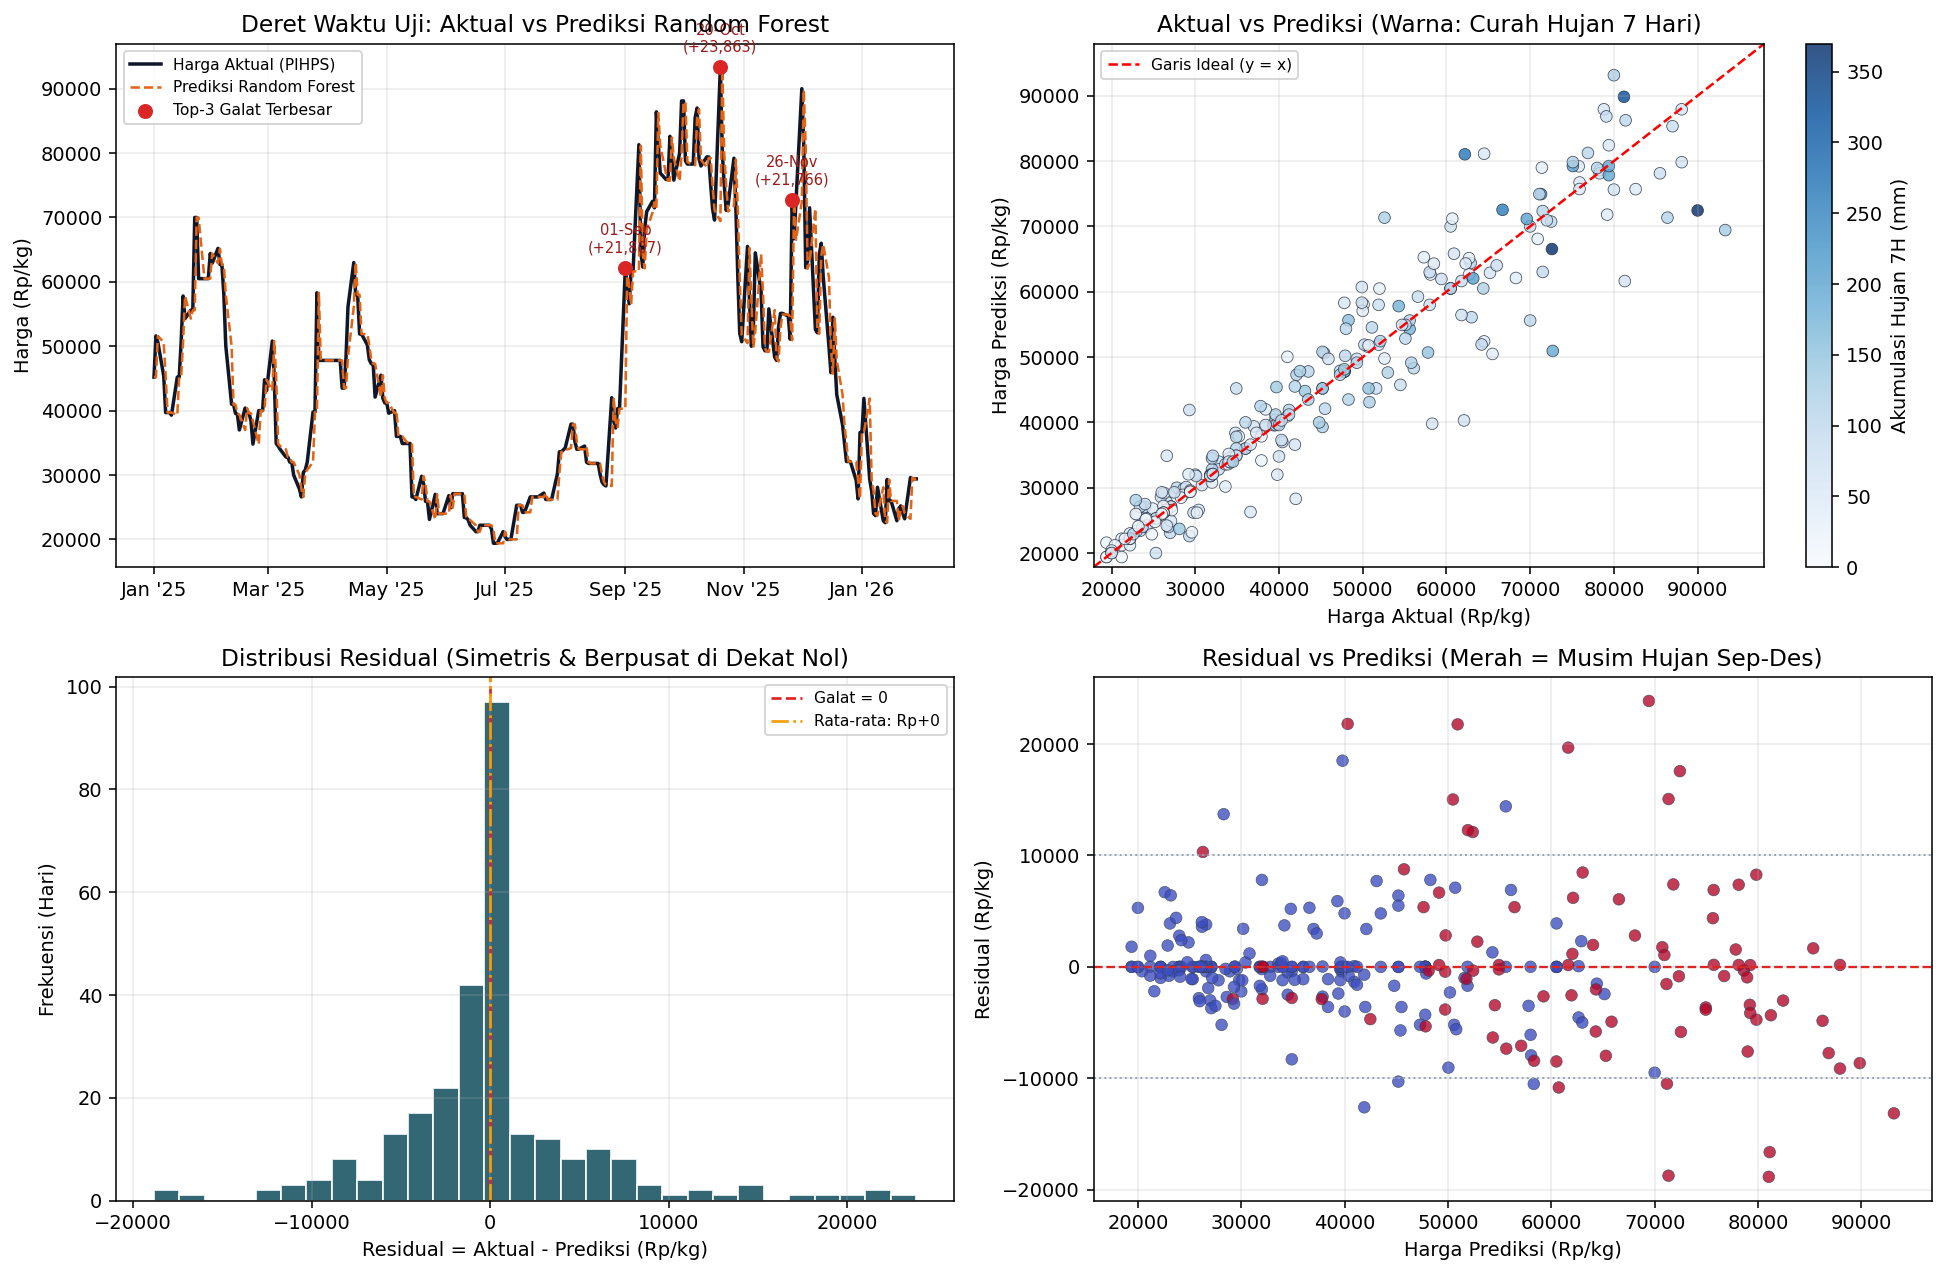

Tersimpan: ..\docs\figures\07_diagnostik_prediksi_dan_residual.png


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.2))

# Panel A: Time series Actual vs Predicted
ax = axes[0, 0]
ax.plot(eval_df["tanggal"], eval_df["aktual"], label="Harga Aktual (PIHPS)", color="#0f172a", linewidth=1.8)
ax.plot(eval_df["tanggal"], eval_df["prediksi_terbaik"], label="Prediksi Random Forest", color="#e36414", linewidth=1.3, linestyle="--")
top3 = eval_df.nlargest(3, "abs_residual")
ax.scatter(top3["tanggal"], top3["aktual"], color="#dc2626", zorder=5, s=45, label="Top-3 Galat Terbesar")
for _, r in top3.iterrows():
    ax.annotate(f"{r['tanggal']:%d-%b}\n({r['residual']:+,.0f})",
                (r["tanggal"], r["aktual"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7.5, color="#991b1b")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax.set_ylabel("Harga (Rp/kg)")
ax.set_title("Deret Waktu Uji: Aktual vs Prediksi Random Forest")
ax.legend(fontsize=8)

# Panel B: Actual vs Predicted Scatter
ax = axes[0, 1]
sc = ax.scatter(eval_df["aktual"], eval_df["prediksi_terbaik"],
                c=eval_df["akumulasi_hujan_7h"].fillna(0), cmap="Blues", alpha=0.82, edgecolors="#1e293b", linewidth=0.4)
lims = [eval_df["aktual"].min() * 0.92, eval_df["aktual"].max() * 1.05]
ax.plot(lims, lims, "r--", linewidth=1.3, label="Garis Ideal (y = x)")
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Akumulasi Hujan 7H (mm)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Harga Aktual (Rp/kg)")
ax.set_ylabel("Harga Prediksi (Rp/kg)")
ax.set_title("Aktual vs Prediksi (Warna: Curah Hujan 7 Hari)")
ax.legend(fontsize=8)

# Panel C: Histogram Residual
ax = axes[1, 0]
ax.hist(eval_df["residual"], bins=30, color="#0f4c5c", alpha=0.85, edgecolor="white")
ax.axvline(0, color="#dc2626", linestyle="--", linewidth=1.4, label="Galat = 0")
ax.axvline(eval_df["residual"].mean(), color="#f59e0b", linestyle="-.", linewidth=1.4,
           label=f"Rata-rata: Rp{eval_df['residual'].mean():+,.0f}")
ax.set_xlabel("Residual = Aktual - Prediksi (Rp/kg)")
ax.set_ylabel("Frekuensi (Hari)")
ax.set_title("Distribusi Residual (Simetris & Berpusat di Dekat Nol)")
ax.legend(fontsize=8)

# Panel D: Residual vs Predicted
ax = axes[1, 1]
ax.scatter(eval_df["prediksi_terbaik"], eval_df["residual"],
           c=eval_df["is_musim_hujan"], cmap="coolwarm", alpha=0.78, edgecolors="#334155", linewidth=0.35)
ax.axhline(0, color="#dc2626", linestyle="--", linewidth=1.2)
ax.axhline(10000, color="#94a3b8", linestyle=":", linewidth=1)
ax.axhline(-10000, color="#94a3b8", linestyle=":", linewidth=1)
ax.set_xlabel("Harga Prediksi (Rp/kg)")
ax.set_ylabel("Residual (Rp/kg)")
ax.set_title("Residual vs Prediksi (Merah = Musim Hujan Sep-Des)")

plt.tight_layout()
out_fig2 = FIG_DIR / "07_diagnostik_prediksi_dan_residual.png"
fig.savefig(out_fig2, bbox_inches="tight")
plt.show()
print("Tersimpan:", out_fig2)


## 4. Segmentasi Galat (*Error Analysis* per Bulan, Musim Hujan, Rezim Harga & Gejolak)

Langkah ini menjawab kapan model bekerja sangat akurat dan pada rezim mana galat prediksi melonjak.

,bulan_str,Hari,Rata_Aktual,MAE,MAPE,RMSE
0,2025-01,23,53256.52,3100.46,5.69,4873.06
1,2025-02,20,44875.00,2549.68,5.76,3630.98
2,2025-03,21,37519.05,3527.99,8.37,5931.46
3,2025-04,22,48936.36,2381.78,4.76,3519.21
4,2025-05,22,30418.18,1499.96,5.35,2545.24
5,2025-06,21,23061.90,875.92,3.77,1399.57
6,2025-07,23,26130.43,842.81,3.09,1682.47
7,2025-08,21,34333.33,1714.13,4.57,3411.61
8,2025-09,22,72518.18,6075.58,8.40,8688.82
9,2025-10,23,75365.22,5227.00,6.95,7552.91



Perbandingan Musim Hujan vs Bulan Lain:


,Periode,Hari,Rata_Aktual,MAE,MAPE
0,Bulan Lain (Jan-Agu),194,36279.90,2128.93,5.66
1,Musim Hujan (Sep-Des),88,63913.64,5995.07,9.49



Perbandingan Rezim Harga:


,rezim_harga,Hari,MAE,MAPE
0,Normal (< Rp50rb),182,1963.36,5.76
1,Tinggi (>= Rp50rb),100,5832.48,8.85



Perbandingan Hari Gejolak vs Tenang:


,rezim_gejolak,Hari,MAE,MAPE
0,Lonjakan (|dY| > Rp5rb),70,9532.72,17.42
1,Tenang (|dY| <= Rp5rb),212,1289.10,3.36


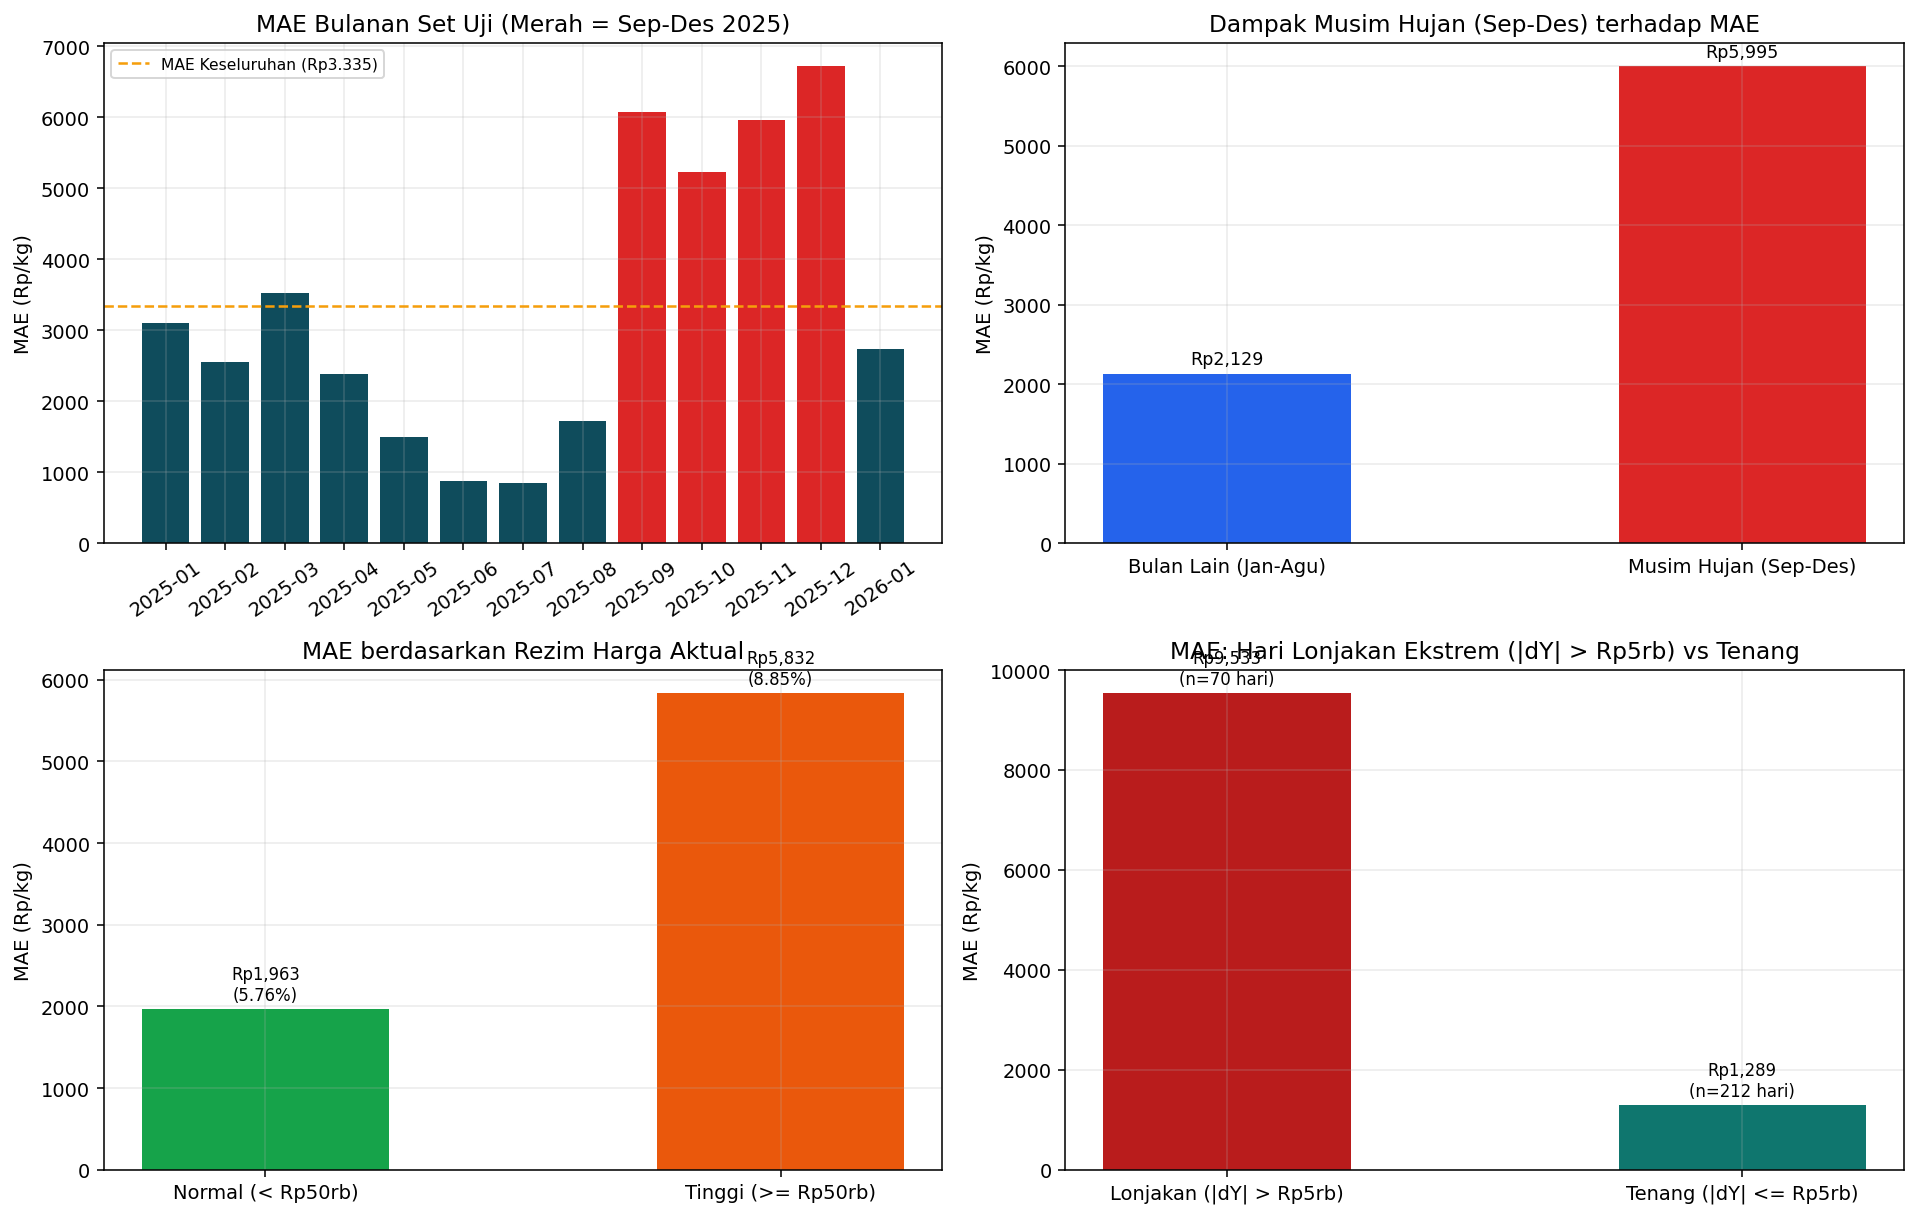

Tersimpan: ..\docs\figures\07_error_per_rezim_dan_bulan.png


In [5]:
bulanan = eval_df.groupby("bulan_str", as_index=False).agg(
    Hari=("tanggal", "count"),
    Rata_Aktual=("aktual", "mean"),
    MAE=("abs_residual", "mean"),
    MAPE=("ape_persen", "mean"),
    RMSE=("residual", lambda s: float(np.sqrt(np.mean(np.square(s))))),
)
display(bulanan.round(2))

musim_grp = eval_df.assign(
    Periode=np.where(eval_df["is_musim_hujan"] == 1, "Musim Hujan (Sep-Des)", "Bulan Lain (Jan-Agu)")
).groupby("Periode", as_index=False).agg(
    Hari=("tanggal", "count"),
    Rata_Aktual=("aktual", "mean"),
    MAE=("abs_residual", "mean"),
    MAPE=("ape_persen", "mean"),
)

harga_grp = eval_df.groupby("rezim_harga", as_index=False).agg(
    Hari=("tanggal", "count"),
    MAE=("abs_residual", "mean"),
    MAPE=("ape_persen", "mean"),
)

gejolak_grp = eval_df.groupby("rezim_gejolak", as_index=False).agg(
    Hari=("tanggal", "count"),
    MAE=("abs_residual", "mean"),
    MAPE=("ape_persen", "mean"),
)

print("\nPerbandingan Musim Hujan vs Bulan Lain:")
display(musim_grp.round(2))
print("\nPerbandingan Rezim Harga:")
display(harga_grp.round(2))
print("\nPerbandingan Hari Gejolak vs Tenang:")
display(gejolak_grp.round(2))

# Visualisasi 3: Error per Rezim dan Bulan
fig, axes = plt.subplots(2, 2, figsize=(13.8, 8.8))

# Bulan MAE
ax = axes[0, 0]
bar_colors = ["#dc2626" if m.endswith(("-09", "-10", "-11", "-12")) else "#0f4c5c" for m in bulanan["bulan_str"]]
ax.bar(bulanan["bulan_str"], bulanan["MAE"], color=bar_colors)
ax.axhline(eval_df["abs_residual"].mean(), color="#f59e0b", linestyle="--", linewidth=1.3, label="MAE Keseluruhan (Rp3.335)")
ax.tick_params(axis="x", rotation=35)
ax.set_ylabel("MAE (Rp/kg)")
ax.set_title("MAE Bulanan Set Uji (Merah = Sep-Des 2025)")
ax.legend(fontsize=8)

# Musim Hujan vs Non
ax = axes[0, 1]
b1 = ax.bar(musim_grp["Periode"], musim_grp["MAE"], color=["#2563eb", "#dc2626"], width=0.48)
ax.set_ylabel("MAE (Rp/kg)")
ax.set_title("Dampak Musim Hujan (Sep-Des) terhadap MAE")
for b in b1:
    ax.annotate(f"Rp{b.get_height():,.0f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")

# Rezim Harga
ax = axes[1, 0]
b2 = ax.bar(harga_grp["rezim_harga"], harga_grp["MAE"], color=["#16a34a", "#ea580c"], width=0.48)
ax.set_ylabel("MAE (Rp/kg)")
ax.set_title("MAE berdasarkan Rezim Harga Aktual")
for b, mape in zip(b2, harga_grp["MAPE"]):
    ax.annotate(f"Rp{b.get_height():,.0f}\n({mape:.2f}%)", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

# Rezim Gejolak
ax = axes[1, 1]
b3 = ax.bar(gejolak_grp["rezim_gejolak"], gejolak_grp["MAE"], color=["#b91c1c", "#0f766e"], width=0.48)
ax.set_ylabel("MAE (Rp/kg)")
ax.set_title("MAE: Hari Lonjakan Ekstrem (|dY| > Rp5rb) vs Tenang")
for b, cnt in zip(b3, gejolak_grp["Hari"]):
    ax.annotate(f"Rp{b.get_height():,.0f}\n(n={cnt} hari)", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

plt.tight_layout()
out_fig3 = FIG_DIR / "07_error_per_rezim_dan_bulan.png"
fig.savefig(out_fig3, bbox_inches="tight")
plt.show()
print("Tersimpan:", out_fig3)


## 5. Bedah 10 Residual Terbesar & Peringkat *Feature Importance*

Selanjutnya kita menelusuri **10 hari dengan galat absolut terbesar** dari `metrics["residual_terbesar"]` beserta konteks cuaca (`Akumulasi_Hujan_7H`), jarak ke Idul Fitri, dan harga pasar hulu.

,tanggal,harga_lag1,aktual,prediksi,residual,ape_persen,akumulasi_hujan_7h,hari_menuju_idul_fitri,hipotesis_penyebab
0,2025-10-20,69600.0,93300.0,69436.7,23863.3,25.577,131.2,152,Guncangan Pasokan Hujan Ekstrem (Hujan 7H >= 1...
1,2025-09-01,40300.0,62100.0,40293.3,21806.7,35.115,67.6,201,Volatilitas Pasokan Awal Musim Hujan (Sep)
2,2025-11-26,51100.0,72700.0,50933.7,21766.3,29.940,189.9,115,Guncangan Pasokan Hujan Ekstrem (Hujan 7H >= 1...
3,2025-09-08,61800.0,81300.0,61627.3,19672.7,24.198,65.1,194,Volatilitas Pasokan Awal Musim Hujan (Sep)
4,2025-12-03,81200.0,62200.0,81033.7,-18833.7,30.279,267.1,108,Koreksi Tajam Pasca-Puncak (Mean Reversion)
5,2025-12-08,71500.0,52600.0,71333.7,-18733.7,35.615,120.5,103,Koreksi Tajam Pasca-Puncak (Mean Reversion)
6,2025-03-26,39800.0,58300.0,39798.2,18501.8,31.736,60.8,5,Lonjakan Permintaan H-5 Idul Fitri
7,2025-12-01,72600.0,90000.0,72433.7,17566.3,19.518,368.5,110,Guncangan Pasokan Hujan Ekstrem (Hujan 7H >= 1...
8,2025-09-09,81300.0,64500.0,81119.0,-16619.0,25.766,56.1,193,Koreksi Tajam Pasca-Puncak (Mean Reversion)
9,2025-09-17,71500.0,86400.0,71338.3,15061.7,17.433,111.6,185,Guncangan Pasokan Hujan Ekstrem (Hujan 7H >= 1...


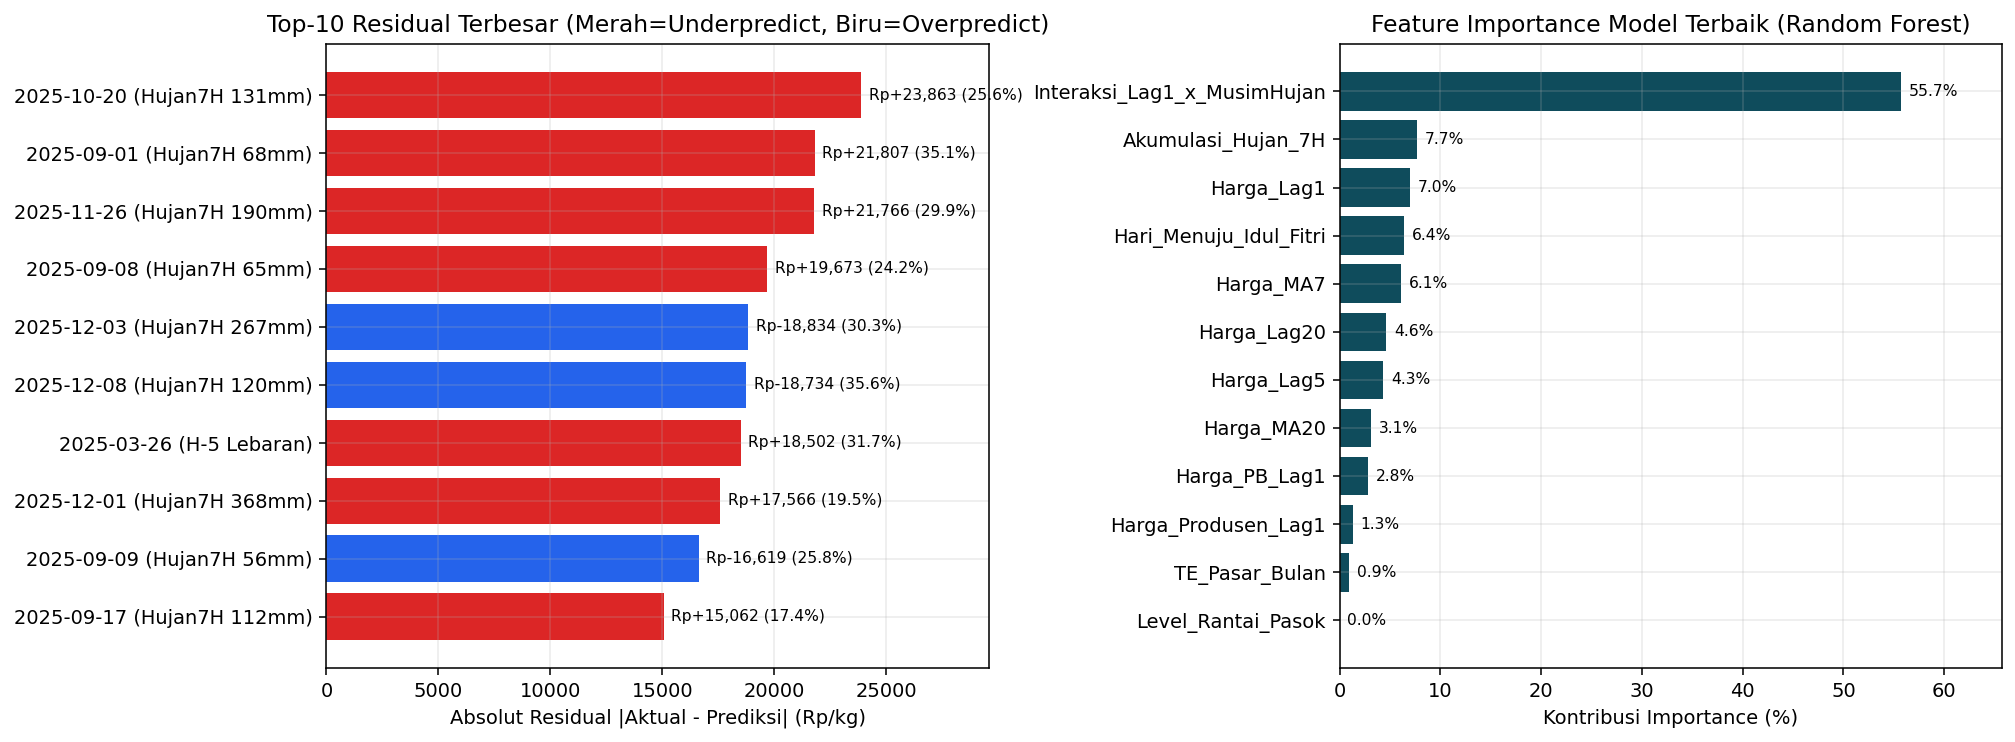

Tersimpan: ..\docs\figures\07_top10_residual_dan_importance.png


In [6]:
top10_df = pd.DataFrame(metrics["residual_terbesar"]).copy()
top10_df["tanggal_dt"] = pd.to_datetime(top10_df["tanggal"])

def klasifikasi_penyebab(row: pd.Series) -> str:
    if row["hari_menuju_idul_fitri"] <= 7:
        return "Lonjakan Permintaan H-5 Idul Fitri"
    if row["residual"] < 0 and row["is_musim_hujan"] == 1:
        return "Koreksi Tajam Pasca-Puncak (Mean Reversion)"
    if row["akumulasi_hujan_7h"] >= 100:
        return "Guncangan Pasokan Hujan Ekstrem (Hujan 7H >= 100mm)"
    return "Volatilitas Pasokan Awal Musim Hujan (Sep)"

top10_df["hipotesis_penyebab"] = top10_df.apply(klasifikasi_penyebab, axis=1)
display(top10_df[[
    "tanggal", "harga_lag1", "aktual", "prediksi", "residual", "ape_persen",
    "akumulasi_hujan_7h", "hari_menuju_idul_fitri", "hipotesis_penyebab"
]])

fi_df = pd.DataFrame(list(metrics["feature_importance"].items()), columns=["Fitur", "Importance"])
fi_df = fi_df.sort_values("Importance", ascending=True)

# Visualisasi 4: Top-10 Residual & Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4))

# Kiri: Top 10 Residuals
top10_plot = top10_df.sort_values("abs_residual", ascending=True).copy()
labels_res = [
    f"{r['tanggal']} (Hujan7H {r['akumulasi_hujan_7h']:.0f}mm)"
    if r["hari_menuju_idul_fitri"] > 7
    else f"{r['tanggal']} (H-{r['hari_menuju_idul_fitri']} Lebaran)"
    for _, r in top10_plot.iterrows()
]
colors_res = ["#dc2626" if r["residual"] > 0 else "#2563eb" for _, r in top10_plot.iterrows()]
bars_r = axes[0].barh(labels_res, top10_plot["abs_residual"], color=colors_res)
axes[0].set_xlabel("Absolut Residual |Aktual - Prediksi| (Rp/kg)")
axes[0].set_xlim(0, top10_plot["abs_residual"].max() * 1.24)
axes[0].set_title("Top-10 Residual Terbesar (Merah=Underpredict, Biru=Overpredict)")
for b, (_, r) in zip(bars_r, top10_plot.iterrows()):
    axes[0].annotate(f"Rp{r['residual']:+,.0f} ({r['ape_persen']:.1f}%)",
                     (b.get_width(), b.get_y() + b.get_height() / 2),
                     xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)

# Kanan: Feature Importance
bars_fi = axes[1].barh(fi_df["Fitur"], fi_df["Importance"] * 100, color="#0f4c5c")
axes[1].set_xlabel("Kontribusi Importance (%)")
axes[1].set_xlim(0, fi_df["Importance"].max() * 100 * 1.18)
axes[1].set_title("Feature Importance Model Terbaik (Random Forest)")
for b in bars_fi:
    w_val = b.get_width()
    axes[1].annotate(f"{w_val:.1f}%", (w_val, b.get_y() + b.get_height() / 2),
                     xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)

plt.tight_layout()
out_fig4 = FIG_DIR / "07_top10_residual_dan_importance.png"
fig.savefig(out_fig4, bbox_inches="tight")
plt.show()
print("Tersimpan:", out_fig4)


## 6. Sintesis Akar Masalah, Keterbatasan, & Rekomendasi Perbaikan (Menuju M13)

### A. Temuan Kunci *Error Analysis*
1. **Dominasi Guncangan Musim Hujan Sep–Des 2025:** **9 dari 10** residual terbesar terjadi pada periode September–Desember 2025, dengan akumulasi hujan 7 hari sangat tinggi (mencapai `189,9 mm` pada 26 Nov, `267,1 mm` pada 3 Des, hingga `368,5 mm` pada 1 Des 2025). MAE pada Sep–Des lebih dari dua kali lipat dibanding bulan Januari–Agustus.
2. **Efek Pembalikan Tajam (*Mean Reversion*) Pasca-Lonjakan:** 3 dari 10 galat terbesar bernilai negatif (`2025-09-09` `-Rp16.619`, `2025-12-03` `-Rp18.834`, `2025-12-08` `-Rp18.734`). Ketika harga kemarin melonjak terlalu tinggi (`Rp71.500–Rp81.300/kg`), pasar langsung terkoreksi keesokan harinya, sedangkan model yang sangat bertumpu pada `Harga_Lag1` cenderung tetap memprediksi dekat harga puncak.
3. **Lonjakan Permintaan H-5 Idul Fitri (`2025-03-26`, `+Rp18.502`):** Menjelang puncak hari raya, permintaan naik mendadak dalam satu hari kerja (`Rp39.800 -> Rp58.300/kg`), melampaui kapasitas respon pola historis linier/pohon pada jangka 1 hari.
4. **Kinerja Tinggi pada Hari Normal:** Pada rezim hari tenang (`|Δy_t| <= Rp5.000/kg`), MAE sangat rendah (jauh di bawah rata-rata keseluruhan), membuktikan model sangat andal untuk operasi pemantauan rutin.

### B. Rekomendasi Teknis Model (M13) & Operasional TPID Kota Medan
- **Untuk Pemodelan M13:**
  1. Uji fitur non-linear pembalikan harga (*lagged 1-day return* $\Delta y_{t-1}$ dan selisih harga terhadap `MA7`) untuk menangkap pola koreksi pasca-lonjakan.
  2. Uji pemangkasan fitur `Level_Rantai_Pasok` yang bernilai konstan (`importance = 0,0`) pada model khusus Pasar Tradisional dan tambahkan indikator interaksi cuaca ekstrem (`Hujan_7H > 150 mm`).
  3. Sajikan **interval ketidakpastian (P10–P90 atau margin ±MAE rezim hujan vs normal)** di antarmuka pengguna agar pengambil kebijakan tidak terpaku pada satu titik angka saat curah hujan ekstrem.
- **Untuk Pemangku Kepentingan (TPID / Pedagang / Konsumen):**
  - Gunakan indikator `Akumulasi_Hujan_7H > 100 mm` selama Sep–Des bersama prediksi dashboard sebagai **sinyal peringatan dini (*early warning*)** agar TPID segera menyiapkan operasi pasar atau realokasi pasokan antar-daerah sebelum lonjakan harga mencapai puncaknya.